# Neural Likelihood Estimation

Train a conditional flow for `p(v_los | log10 R, theta, log r*, sigma_v)` on the
group's HDF5 datasets, then samples `p(theta | one galaxy)` from it.

In [1]:
%matplotlib inline
import sys
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import torch

REPO_ROOT = Path.cwd().parent        # the repo root
sys.path.insert(0, str(REPO_ROOT))

from nle_dsph import api
from nle_dsph import datasets
from nle_dsph.transforms import StarBatch, build_transformation

torch.set_num_threads(8)        # shared node; the cgroup caps us at 38 cores

## 1. Read in the data

The dataset is stored in HDF5 format `data.<i>.h5`, which is a binary storage format
for large dataset. It is less human readable than text formats like CSV, but it is more
efficient at storing and accessing large amounts of data.

Node features (i.e. stars) are stored flat and indexed by `ptr`. 
For example, stars from galaxy `i` are found in the range `ptr[i]:ptr[i+1]`.
Graph features (i.e. per galaxy) are stored as 1-D arrays of length `n_galaxies`.

You can use `read_datasets` to read the HDF5 files into dictionaries of arrays.

In [2]:
data_root = '/home/jupyter-tvnguyen/scratch/sbi_dsph/training_datasets'
data_name = '8p_ZhaoPlumCOM_v4'
workdir = 'example_runs'

In [3]:
# read a single dataset
node_feats, graph_feats = datasets.read_datasets(data_root, data_name, num_datasets=1)

print('node features :', {k: v.shape for k, v in node_feats.items()})
print('graph features:', sorted(graph_feats))
print(f"\n{len(graph_feats['num_stars']):,} galaxies, "
      f"{len(node_feats['pos']):,} stars "
      f"({graph_feats['num_stars'].min()}-{graph_feats['num_stars'].max()} "
      f"per galaxy, median {int(np.median(graph_feats['num_stars']))})")

100%|██████████| 1/1 [00:00<00:00,  2.44it/s]


node features : {'pos': (9858199, 3), 'vel': (9858199, 3)}
graph features: ['df_beta0', 'df_log_ra', 'dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm', 'dm_log_rho0', 'num_stars', 'ptr', 'stellar_log_ra_kpc', 'stellar_log_rstar', 'stellar_log_rstar_kpc']

100,000 galaxies, 9,858,199 stars (60-142 per galaxy, median 98)


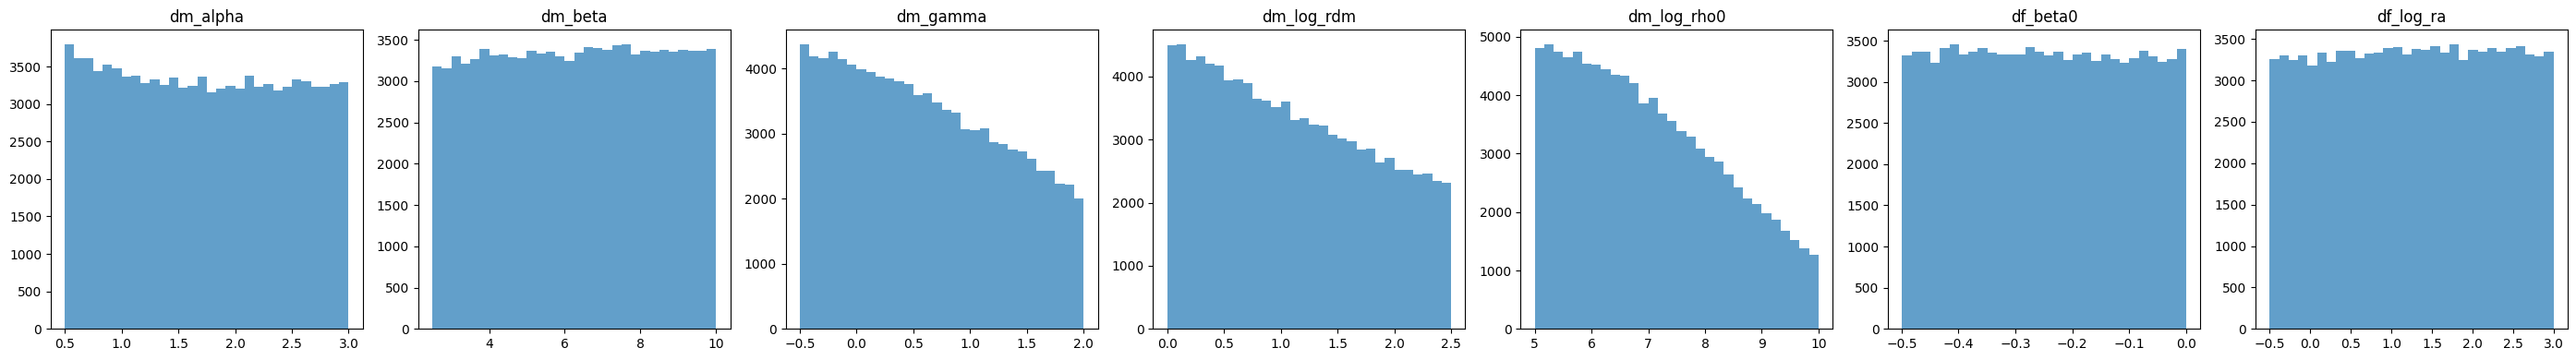

In [4]:
# example: plot the distribution of each graph feature
# note that I have a preprocess cut on my data so the prior distribution is not uniform
labels = [
    'dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm', 'dm_log_rho0',
    'df_beta0', 'df_log_ra',]

fig, axes = plt.subplots(1, len(labels), figsize=(4 * len(labels), 4))
for i, label in enumerate(labels):
    axes[i].hist(graph_feats[label], bins=30, alpha=0.7)
    axes[i].set_title(label)
plt.tight_layout()

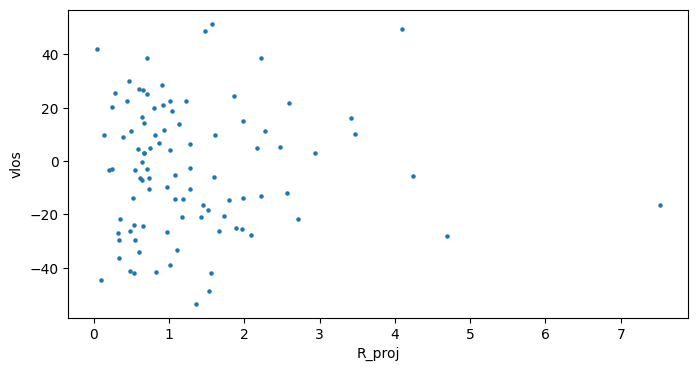

In [6]:
# example: plot the position and velocity of stars in a single galaxy
index_gal = 0
ptr = graph_feats['ptr']
start, end = ptr[index_gal], ptr[index_gal + 1]
pos = node_feats['pos'][start:end]
vel = node_feats['vel'][start:end]
R_proj = np.sqrt(pos[:, 0]**2 + pos[:, 1]**2)
vlos = vel[:, 2]

fig, ax = plt.subplots(1, figsize=(8, 4))
ax.scatter(R_proj, vlos, s=5)
ax.set_xlabel('R_proj')
ax.set_ylabel('vlos')
plt.show()

**NOTE**: `labels` vs `cond_labels`. For NPE, `labels` are the parameters being inferred, while `cond_labels` are the measured quantities held fixed during inference. However, here both are treated as context for the flow.

For the older models, you used to hold `cond_labels` fixed during inference. However, the proper procedure is to construct a special 
prior that properly accounts for the measured quantities as context. You can see how this is done below.

## 2. The config

`get_config()` is an ordinary Python function, so a config file and a
notebook are not competing interfaces: load it, edit the fields in this cell,
and the object you trained with is the object that gets snapshotted.

`load_config` rejects an override that names no field (a typo like
`num_stepz=300` would otherwise do nothing and train with the default).
Nested fields are edited directly on the object.

The settings below are a **smoke test**: one shard, a small flow, 300 steps
on the CPU, a few minutes. They are not a model to do science with.

In [23]:
config = api.load_config(
    'example_config.py',
    data_root=data_root,
    num_datasets=2,            # 200k galaxies
    workdir=workdir,
    debug=True,              # wandb off; drop this for a run you keep
    accelerator='cpu',   # IMPORTANT: On Tucana, change this to 'mps' for Apple Silicon GPUs
    train_batch_size=16384,   # the step is launch-bound; go wide
    eval_batch_size=32768,
    train_frac=0.9,
    num_epochs=-1,
    num_steps=15_000,
    data_on_device=True,     # whole dataset in memory, batched by index
)

print('labels     :', config.labels)
print('cond_labels:', config.cond_labels)
print('modeling  : p(v_los | log10 R, theta, cond, sigma_v)'
      if config.model.condition_on_radius else
      'modeling  : p(x, y, v_los | theta, cond, sigma_v)')

print('\nFull Config:')
print('-' * 40)
print(config)

labels     : ('dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm', 'dm_log_rho0', 'df_beta0', 'df_log_ra')
cond_labels: ('stellar_log_rstar_kpc',)
modeling  : p(v_los | log10 R, theta, cond, sigma_v)

Full Config:
----------------------------------------
accelerator: cpu
checkpoint: null
cond_labels: !!python/tuple
- stellar_log_rstar_kpc
data_name: 8p_ZhaoPlumCOM_v4
data_on_device: true
data_root: /home/jupyter-tvnguyen/scratch/sbi_dsph/training_datasets
debug: true
enable_progress_bar: true
entity: sbi_dsph
eval_batch_size: 32768
gradient_clip_val: 0.5
init: 0
labels: !!python/tuple
- dm_alpha
- dm_beta
- dm_gamma
- dm_log_rdm
- dm_log_rho0
- df_beta0
- df_log_ra
model:
  condition_on_position: true
  condition_on_radius: true
  context_embedding:
    act_name: relu
    batch_norm: false
    dropout: 0.0
    hidden_sizes:
    - 128
    - 128
    output_size: 64
  flows:
    activation: tanh
    flow_type: spline
    hidden_features:
    - 128
    - 128
    num_bins: 8
    num_transforms:

In [24]:
# You can also override the config like this
# here I will modify the flow to use a smallerone
print('Old config:')
print('context embedding hidden sizes:', config.model.context_embedding.hidden_sizes)
print('flows num transforms:', config.model.flows.num_transforms)
print('flows hidden features:', config.model.flows.hidden_features)

config.model.context_embedding.hidden_sizes = [64, 64]
config.model.flows.num_transforms = 3
config.model.flows.hidden_features = [64, 64]

print('\nNew config:')
print('context embedding hidden sizes:', config.model.context_embedding.hidden_sizes)
print('flows num transforms:', config.model.flows.num_transforms)
print('flows hidden features:', config.model.flows.hidden_features)

Old config:
context embedding hidden sizes: [128, 128]
flows num transforms: 4
flows hidden features: [128, 128]

New config:
context embedding hidden sizes: [64, 64]
flows num transforms: 3
flows hidden features: [64, 64]


Anything that runs longer than this notebook should go through the script
instead, which reads the same config file and writes the same run directory:

```bash
./slurm/train_nle.sh configs/nle_8p_v4.py --config.num_steps=100000
```
`--config.<field>=<value>` is the command-line twin of the overrides above. Useful if you want to run over different settings without modifying the config file directly. For more info, refer to the `ml_collections` github: https://github.com/google/ml_collections

**NOTE 1**: The script also detaches the process by default, so it will continue running even if you log out. 

**NOTE 2**: Despite the naming, there is no actual SLURM on Ting's servers. The script will run locally and simulate the SLURM environment.

**The rest of the config.** `example_config.py` carries a comment on every
field, and `CONFIG.md` in this directory has the same notes grouped into
tables. Worth a skim once; you will not need most of it day to day.

The two fields worth knowing before section 3 are `model.condition_on_position`
and `model.condition_on_radius`, which decide what the flow actually models:

| `condition_on_position` | `condition_on_radius` | the model is |
|---|---|---|
| `False` | (ignored) | `p(x, y, v \| theta, ...)` |
| `True` | `False` | `p(v \| x, y, theta, ...)` |
| `True` | `True` | `p(v \| log10 R, theta, ...)` |

This config uses the last row.

## 3. Train the model

A single call of `api.train` will do the following:

1. Set up the data loaders. This includes the normalization dictionary for `x` and `theta`.
2. Set up the normalizing flow model
3. Set up the Pytorch Lightning trainer
4. Train the model using the trainer.

It will also save the configuration snapshot and return the run directory, so you can later inspect the training results and checkpoints.

In [ ]:
run_dir = api.train(config, config_path='example_config.py')
run_dir

The run directory includes everything you need to reproduce the run. 


In [ ]:
for path in sorted(run_dir.rglob('*')):
    size = path.stat().st_size / 1e6
    print(f'  {path.relative_to(run_dir)}   ({size:.1f} MB)')

with open(run_dir / 'config_snapshot.json') as f:
    snapshot = json.load(f)

print('\nsnapshot has', len(snapshot), 'top-level fields, including')
for key in ('data_name', 'num_datasets', 'labels', 'seed_data', 'num_steps'):
    print(f'  {key:14s} {snapshot[key]}')

`load_model` takes the directory and returns the trained model. 

In your code, the normalization dictionary has to be recomputed from the training data. 
This is okay but in general, it is better to store the normalization dictionary along with the model checkpoint 
so that it can be directly loaded without recomputation. It is also much safer, as it avoids potential inconsistencies between the training data and the normalization dictionary.


In [ ]:
model, snapshot = api.load_model(run_dir)

print('target  :', model.target_fields)
print('context :', model.context_fields)
print('norm_dict from the checkpoint:', sorted(model.norm_dict)[:4], '...')

## 6. Example: inference on one galaxy

The API takes in an `Observation` objectm which is a
plain dataclass. You will need to input all the required fields listed below.

| field | shape | units | what it is |
|---|---|---|---|
| `vlos_kms` | `(N,)` float64 | km/s | line-of-sight velocity |
| `vlos_err_kms` | `(N,)` float32 | km/s | per-star measurement sigma |
| `log_rstar_kpc` | scalar | log10 kpc | half-light radius, the model's `cond` |
| `pos_kpc` | `(N, 2)` float32 | kpc | tangent-plane position, `(X, Y)` |
| `R_proj_kpc` | `(N,)` float32 | kpc | projected radius |
| `use` | `str` | — | `'position'` or `'radius'`, which one the model gets |
| `log_rstar_err_dex` | scalar | dex | photometric error on `log_rstar_kpc` |
| `name` | `str` | — | used for the output file name |
| `theta_true` | `(n_labels,)` or `None` | normalized units | (optional) true labels, for mocks only |

**NOTE**: `pos_kpc` and `R_proj_kpc` are separate inputs. 
If your model config has `condition_on_position=True` AND
`condition_on_radius=True`, the model conditions on the projected radius, so
you must provide `R_proj_kpc` and set `use='radius'`. Passing `pos_kpc` with
`use='position'` while `R_proj_kpc` is set now raises: the model would
recompute the radius as `|pos|` and your measured `R_proj_kpc` would never
be read. Give only `pos_kpc` and the radius is derived from it deliberately,
which is what training does with the projected `(X, Y)`.

(`condition_on_radius=True` with `condition_on_position=False` is not a
valid config -- `NLE.__init__` raises on it.)

**NOTE**: `vlos_err_kms` is **linear sigma in km/s, not log10**. The flow
conditions on sigma itself, so a 1 km/s error is fed in as `1.0`. The
`jeffreys_varied` setting in the config names the distribution sigma is
*drawn* from during training, not how it is represented.

Check this against whatever produced your catalog. An sbi-style pipeline
that appends `log10(sigma_v)` to theta hands you logs, and passing those
here fails silently: 1 km/s arrives as `0.0`, normalizes to the bottom of
the trained range, every star reads as near-noiseless, and the posterior
comes out tighter than the data supports.


In [ ]:
import pandas as pd
from dsph_analysis import kinematic_io

In [ ]:
catalog_dir = '/raid5b/users/tvnguyen/sbi_dsph/vr_catalogs/mock/icrs/draco1_walker23_icrs'
profile = 'CuspOM'

meta = kinematic_io.load_meta('draco_1')
data = kinematic_io.load_kinematic_data(
    f'{catalog_dir}/{profile}_mock_catalog.csv', meta, source='mock_icrs',
    vlos_abs_max=50.0, apply_perspective_corr=True)

# measured half-light radius and its error
rhalf = meta.rhalf_kpc.to_value('kpc')
rhalf_err = 0.5 * (meta.rhalf_kpc_em.to_value('kpc') + meta.rhalf_kpc_ep.to_value('kpc'))

# read the truth parameters for the mock catalog
truth = pd.read_csv(
    f'{catalog_dir}/mock_catalog_params.csv').set_index('profile').loc[profile]
theta_true = np.array([
    truth.alp, truth.bet, truth.gam,
    np.log10(truth.r_s / rhalf),       # dm_log_rdm, in r_star units
    np.log10(truth.rho_s),
    truth.beta0,
    np.log10(truth.r_a / rhalf),       # df_log_ra, in r_star units
], dtype=np.float32)

# create the observation object
obs = api.Observation(
    R_proj_kpc=data.R_proj.to_value('kpc').astype(np.float32),
    vlos_kms=data.vlos.to_value('km/s').astype(np.float64),
    vlos_err_kms=data.vlos_err.to_value('km/s').astype(np.float32),
    log_rstar_kpc=float(np.log10(rhalf)),
    log_rstar_err_dex=float(rhalf_err / (rhalf * np.log(10.0))),
    name=f'dra_mockicrs_walker23_{profile}',
    theta_true=theta_true
)

print(f'{obs.name}: {obs.n_stars} stars, use={obs.use!r}')
print(f'  R_proj   {obs.R_proj_kpc.min():.3f} - '
      f'{obs.R_proj_kpc.max():.3f} kpc')
print(f'  v_los    median {np.median(obs.vlos_kms):+.2f} km/s'
      '   (systemic-subtracted)')
print(f'  sigma_v  {obs.vlos_err_kms.min():.2f} - '
      f'{obs.vlos_err_kms.max():.2f} km/s')
print(f'  log10 r_star = {obs.log_rstar_kpc:.4f} '
      f'+- {obs.log_rstar_err_dex:.4f} dex  (r_star = {rhalf * 1e3:.0f} pc)')


`theta_true` is optional and exists only so the plots below can mark the
answer. For a real dwarf it is `None`, the truth markers in section 10
simply go away, and nothing else changes.

**NOTE**: check the truth lands inside the prior box, as above. An
isotropic mock has `r_a = inf`, so `df_log_ra` is `+inf` and there is no
finite truth to mark; the `OM` profiles put `r_a = r_star` exactly, which is
why this one gives a clean `0`.

### 6a. Creating the likelihood and prior distribution

The NLE evaluate the likelihood:

```
p(v_i | R_i, labels, v_sys, log_rstar, sigma_i)
    = p_flow(v_i - v_sys | log10 R_i, labels, log_rstar, sigma_i)
```

summed over the galaxy's stars. 

**IMPORTANT**: note the ordering of the conditions. If you are modifying the 
likelihood to run tests, make sure that the ordering of the conditions remains consistent.
You can also look at the `01_nle_internals.ipynb` notebook to get a clearer picture.

For the prior distribution, the ordering should be 

```
[ labels... , v_sys , log_rstar ]
```

You can see the example below. 

In [ ]:
import pocomc as pc
from scipy.stats import truncnorm, uniform

# the 8p_ZhaoPlumCOM_v4 box, (low, high) for each parameter
prior_box = {
    'dm_alpha': (0.5, 3.0),
    'dm_beta': (2.5, 10.0),
    'dm_gamma': (-0.5, 2.0),
    'dm_log_rdm': (0.0, 2.5),
    'dm_log_rho0': (5.0, 10.0),
    'df_beta0': (-0.499, 0.0),
    'df_log_ra': (-0.5, 3.0),
}
prior_min = np.array([prior_box[name][0] for name in config.labels])
prior_max = np.array([prior_box[name][1] for name in config.labels])
dists = [uniform(lo, hi - lo) for lo, hi in zip(prior_min, prior_max)]

# v_sys as a nuisance parameter
v_sys_halfwidth = 50.0
dists.append(uniform(-v_sys_halfwidth, 2 * v_sys_halfwidth))

# log_rstar over the photometry, truncated at prior_n_sigma and at the
# r_star range this checkpoint was trained on
prior_n_sigma = 5.0
trained_low, trained_high = api.cond_box(model)
mu, sigma = obs.log_rstar_kpc, obs.log_rstar_err_dex
win_low = max(trained_low, mu - prior_n_sigma * sigma)
win_high = min(trained_high, mu + prior_n_sigma * sigma)
dists.append(truncnorm((win_low - mu) / sigma, (win_high - mu) / sigma,
                       loc=mu, scale=sigma))

# create the prior object using the defined distributions
prior = pc.Prior(dists)

print(f'trained r_star box : [{trained_low:.3f}, {trained_high:.3f}]')
print(f'sampled over       : [{win_low:.3f}, {win_high:.3f}]')
print('prior dimensions   :', prior.dim,
      f'= {len(config.labels)} labels + v_sys + log_rstar')

print('\ntruth, and whether it is within the prior range:')
for name, value, lo, hi in zip(config.labels, obs.theta_true,
                               prior_min, prior_max):
    flag = 'ok' if lo <= value <= hi else 'OUTSIDE'
    print(f'  {name:14s} {value:8.3f}   [{lo:6.2f}, {hi:6.2f}]  {flag}')

In [ ]:
# this will use pocomc to sample the posterior
result = api.sample_posterior(
    model, obs, prior, labels=config.labels,
    n_effective=512, n_active=128, n_total=1024, seed=0)

print('posterior :', result['posterior'].shape, '->', result['labels'])
print('nuisance  :', result['nuisance'].shape, '->',
      result['nuisance_labels'])
print(f"log Z     : {result['log_evidence']:.2f} "
      f"+- {result['log_evidence_err']:.2f}")

q = np.percentile(result['posterior'][:, -1], [16, 50, 84])
print(f'\nlog r_star posterior: {q[1]:.3f} -{q[1] - q[0]:.3f} '
      f'+{q[2] - q[1]:.3f}  (measured {obs.log_rstar_kpc:.3f})')

In [ ]:
out_path = api.save_posterior('inference', obs, result)

with np.load(out_path, allow_pickle=True) as saved:
    for key in saved.files:
        print(f'  {key:24s} {np.shape(saved[key])}')
print('\nwrote', out_path)

## 6b. Visualizing the posterior and Jeans profiles

In [ ]:
from dsph_analysis import vdisp, vkurtosis
from dsph_analysis.sph_model import GeneralizedOMJeans

n_profile_draws = 400
r_vec = np.logspace(-2, 0.7, 60)


def jeans_theta(alp, bet, gam, log_rdm_kpc, log_rho0, beta0, log_ra_kpc,
                log_rstar_kpc):
    """The 12-element vector GeneralizedOMJeans takes, from one draw.

    Every radius here is log10 kpc, not r_star units. rho_s is in the
    solver's 1e7 Msun/kpc^3, hence the -7. beta is carried as 2**beta,
    and 2**1 = 2 in the second slot is the Osipkov-Merritt beta_inf = 1.
    """
    return np.array([
        log_rho0 - 7.0, log_rdm_kpc, alp, bet, gam, log_ra_kpc,
        2.0 ** beta0, 2.0, 10.0 ** log_rstar_kpc, 0.0, 0.0, 0.0])


def jeans_profiles(theta12, r_vec):
    """rho, enclosed mass, beta(r) and the two LOS moments."""
    jeans = GeneralizedOMJeans(theta12)
    return {
        'rho': jeans.rho(r_vec) * 1e7,
        'mass': jeans.M(r_vec) * 1e7,
        'beta_ani': jeans.beta(r_vec),
        'sigma_los': np.sqrt(jeans.sigma2_los(r_vec)),
        'kurtosis_los': jeans.kurtosis_los(r_vec),
    }


def to_kpc(rows, log_rstar):
    """Posterior radii from r_star units to log10 kpc."""
    out = np.asarray(rows, dtype=float).copy()
    out[:, 3] += log_rstar
    out[:, 6] += log_rstar
    return out


# the posterior's own log_rstar column rescales each row
draws = result['posterior'][:n_profile_draws]
draws_kpc = to_kpc(draws[:, :7], draws[:, -1])

curves = [jeans_profiles(jeans_theta(*row, log_rstar), r_vec)
          for row, log_rstar in zip(draws_kpc, draws[:, -1])]
profiles = {key: np.array([c[key] for c in curves]) for key in curves[0]}
profiles['slope'] = np.gradient(np.log(profiles['rho']), np.log(r_vec), axis=-1)

truth_kpc = to_kpc(obs.theta_true[None, :], obs.log_rstar_kpc)[0]
truth = jeans_profiles(
    jeans_theta(*truth_kpc, obs.log_rstar_kpc), r_vec)
truth['slope'] = np.gradient(np.log(truth['rho']), np.log(r_vec))

binned_sigma = vdisp.calc_vdisp_los_binned(
    obs.R_proj_kpc, obs.vlos_kms, obs.vlos_err_kms,
    nbins_min=6, nbins_max=6, verbose=False)
binned_kappa = vkurtosis.calc_kurtosis_los_binned(
    obs.R_proj_kpc, obs.vlos_kms, obs.vlos_err_kms,
    sampler='pocomc', method='fast', nbins_min=6, nbins_max=6,
    verbose=False)

print('profiles:', {k: v.shape for k, v in profiles.items()})
print('binned bins:', len(binned_sigma['R_mid']))

In [ ]:
band_color = '#332288'

def plot_bands(ax, x, samples, color=band_color):
    """Median with 68% and 95% bands, widest first so the inner band
    layers on top and reads as more opaque."""
    for lo, hi in ((2.5, 97.5), (16, 84)):
        low = np.percentile(samples, lo, axis=0)
        high = np.percentile(samples, hi, axis=0)
        ax.fill_between(x, low, high, color=color, alpha=0.15, lw=0)
        ax.plot(x, low, color=color, lw=1.2, alpha=0.9)
        ax.plot(x, high, color=color, lw=1.2, alpha=0.9)
    ax.plot(x, np.median(samples, axis=0), color=color, lw=2.4)


fig, axes = plt.subplots(2, 3, figsize=(17, 9.5), sharex=True)
ax_rho, ax_slope, ax_mass, ax_beta, ax_sigma, ax_kappa = axes.ravel()

panels = (
    (ax_rho, 'rho', r'Density [M$_\odot$/kpc$^3$]',
     '(a) dark-matter density', True),
    (ax_slope, 'slope', r'$d\ln\rho\,/\,d\ln r$',
     '(b) logarithmic slope', False),
    (ax_mass, 'mass', r'Enclosed mass [M$_\odot$]',
     '(c) enclosed mass', True),
    (ax_beta, 'beta_ani', r'Anisotropy $\beta(r)$',
     '(d) orbital anisotropy', False),
    (ax_sigma, 'sigma_los', r'LOS dispersion [km s$^{-1}$]',
     '(e) line-of-sight dispersion', False),
    (ax_kappa, 'kurtosis_los', 'LOS kurtosis (Gaussian = 3)',
     '(f) line-of-sight kurtosis', False),
)

for ax, key, ylabel, heading, log_y in panels:
    plot_bands(ax, r_vec, profiles[key])
    ax.plot(r_vec, truth[key], color='k', ls='--', lw=2)
    ax.axvspan(obs.R_proj_kpc.min(), obs.R_proj_kpc.max(),
               color='0.85', alpha=0.35, lw=0, zorder=0)
    ax.axvline(10 ** obs.log_rstar_kpc, color='0.4', ls='-.', lw=1.2)
    ax.axvline(0.15, color='0.4', ls='--', lw=1.2)
    ax.set_xscale('log')
    ax.set_xlim(1e-2, 1e1)
    ax.set_ylabel(ylabel)
    ax.set_title(heading, fontsize=17)
    if log_y:
        ax.set_yscale('log')

for ax, group, key in ((ax_sigma, binned_sigma, 'sigma'),
                       (ax_kappa, binned_kappa, 'kappa')):
    ax.errorbar(group['R_mid'], group[key],
                xerr=(group['R_em'], group['R_ep']),
                yerr=(group[f'{key}_em'], group[f'{key}_ep']),
                fmt='o', color='k', alpha=0.75, markersize=6, zorder=5)

ax_beta.axhline(0, color='0.6', lw=0.8)
ax_kappa.axhline(3, color='0.6', lw=0.8)
# the two LOS panels are read against the binned points, so frame them
# on what was measured; beyond the outermost star the band extrapolates
# hard enough to squash the data into the floor
for ax, key, group in ((ax_sigma, 'sigma_los', binned_sigma),
                       (ax_kappa, 'kurtosis_los', binned_kappa)):
    name = 'sigma' if key == 'sigma_los' else 'kappa'
    low = min(np.min(np.asarray(group[name]) - group[f'{name}_em']),
              np.median(profiles[key], axis=0).min())
    high = max(np.max(np.asarray(group[name]) + group[f'{name}_ep']),
               np.median(profiles[key], axis=0).max())
    pad = 0.2 * (high - low)
    ax.set_ylim(max(0.0, low - pad), high + pad)

for ax in axes[1]:
    ax.set_xlabel(r'Radius [kpc]')

handles = [
    Line2D([], [], color=band_color, lw=2.4, label='NLE posterior'),
    Line2D([], [], color='k', ls='--', lw=2, label='injected truth'),
    Line2D([], [], marker='o', ls='', color='k', label='binned data'),
    Line2D([], [], color='0.4', ls='-.', lw=1.2, label=r'$r_{1/2}$'),
    Line2D([], [], color='0.4', ls='--', lw=1.2, label='150 pc'),
    Patch(facecolor='0.85', label='radial range of the stars'),
]
fig.suptitle(obs.name, fontsize=18)
# leave a strip at the bottom for the legend: tight_layout does not
# know about a figure-level legend and will run the x labels into it
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.legend(handles=handles, loc='lower center', ncol=6,
           bbox_to_anchor=(0.5, 0.0), fontsize=15)

## What you will need to change

| | this notebook | production |
|---|---|---|
| `num_datasets` | 1 | 20-57 |
| `num_steps` | 15_000 | 100k-500k |
| `accelerator` | `'cpu'` | `'gpu'` on a CUDA device or `'mps'` on Apple Silicon |
| `debug` | `True` | `False`|
| flow | 3 x [64, 64] | 4 x [128, 128] |
| launched from | this notebook | `./slurm/train_nle.sh` |
| pocomc | 512 / 128 / 1024 | `n_effective=2048`, `n_active=512` |
| conditioning | `'gaussian'`, 0.02 dex | `'gaussian'`, the target's own LVDB error |

Everything else is identical: the config file, the run directory layout,
`load_model`, `Observation`, `sample_posterior`, the posterior `.npz`.